# 02 · Student distillation: a query encoder the board can run

On the board the corpus side is precomputed (notebook 01), so only the live input needs an encoder. The **student**
is distilled from the music2latent encoder (the **teacher**): it maps the 80-band log-mel spectrum of a frame to the
teacher's 64-dimensional latent of the same frame. It is a multilayer perceptron with two hidden layers of 256 units,
trained under MSE + 0.3 (1 − mean-centred cosine), exported to RTNeural's JSON format and run in C++ on the board.

Mel input was chosen because the board computes it with one 4096-point FFT and a filterbank
(`distillation/features.py`, and in C++ `plugin/src/MelFrontend.cpp`).

This notebook builds mel–latent pairs from the demo signal, trains a small student on them, counts its parameters and
multiply–accumulates, exports it and checks the export against PyTorch. Then it opens the paper's students
(`weights/`, CC BY-NC 4.0) and shows that they round-trip exactly.

In [1]:
import json, tempfile, time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

from analysis import demo, report
from corpus_builder import elkgrain
from distillation import ab_common, features as F, student as S
from distillation.int8_table import load_student_np

torch.manual_seed(0)
pk = elkgrain.ElkGrainPack(demo.ensure_pack())
print(pk)

ElkGrainPack(demo.elkgrain: 633 grains, unit=1, hop48=4486, margin48=480, 3 files, 59.3s audio, 6.0 MB)


## 1. Mel–latent pairs

`features.frame_features` computes, for every latent frame, a 4096-sample window start-aligned to the codec's frame
grid (the same `int(i * hop)` expression as the instrument's silence gate), its log-mel spectrum (80 bands, 20 Hz–16
kHz), 9 spectral descriptors (for the ridge map) and 13 MFCCs (for the MFCC baseline). `pack_pair_table` selects the
rows of the pack's grains, so each mel row lines up with the latent stored in the pack.

The demo corpus is the training set and the three held-out demo queries are the validation set.

training pairs 633 (demo corpus), validation pairs 255 (held-out demo queries)
feature tables per frame: {'feat89': 89, 'mel80': 80, 'mfcc13': 13}


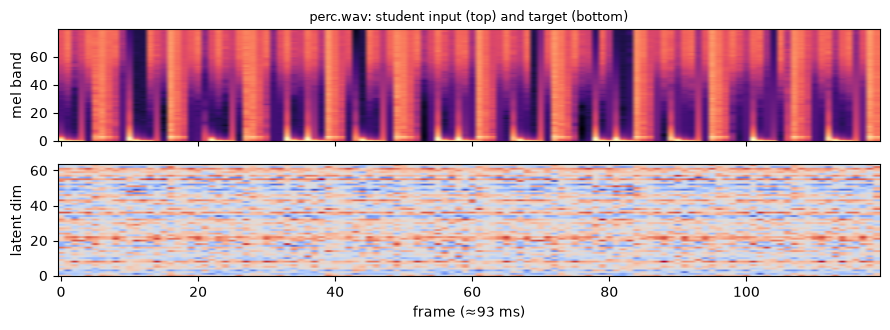

In [2]:
tab = ab_common.pack_pair_table(pk, demo.CORPUS_DIR, F.frame_features)
X_tr, Y_tr = tab["mel80"], np.asarray(pk.raw)                  # [N, 80] log-mel, [N, 64] teacher latents
queries = demo.encode_queries()
X_va = np.concatenate([q["mel80"] for q in queries.values()])
Y_va = np.concatenate([q["lat"].T for q in queries.values()])
print(f"training pairs {len(X_tr)} (demo corpus), validation pairs {len(X_va)} (held-out demo queries)")
print("feature tables per frame:", {k: v.shape[1] for k, v in tab.items() if k != "file_idx"})

f0 = tab["file_idx"] == 0
fig, axes = plt.subplots(2, 1, figsize=(9, 3.4), sharex=True)
axes[0].imshow(X_tr[f0][:120].T, aspect="auto", origin="lower", cmap="magma"); axes[0].set_ylabel("mel band")
axes[1].imshow(Y_tr[f0][:120].T, aspect="auto", origin="lower", cmap="coolwarm"); axes[1].set_ylabel("latent dim")
axes[1].set_xlabel("frame (≈93 ms)"); axes[0].set_title(f"{pk.meta['files'][0]['name']}: student input (top) and target (bottom)", fontsize=9)
fig.tight_layout()

## 2. Training

`student.MLP` and `student.composite_loss` are the paper's model and loss (`distillation/student.py`). The input is
standardised with the training set's mean and standard deviation (stored in the export, foldable into the first
layer). The paper's training loop (`student.train_mlp`: AdamW, lr 2e-3, cosine schedule, early stopping on a
file-level validation split) is reproduced here on the demo pairs, on the CPU.

In [3]:
mu, sd = X_tr.mean(0), X_tr.std(0) + 1e-8
xt, yt = torch.tensor((X_tr - mu) / sd), torch.tensor(Y_tr)
xv, yv = torch.tensor((X_va - mu) / sd), torch.tensor(Y_va)
centre = yt.mean(0)

model = S.MLP()
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=300)
best, best_state, patience, t0 = np.inf, None, 0, time.time()
for ep in range(300):
    model.train()
    perm = torch.randperm(len(xt))
    for i in range(0, len(xt), 128):
        idx = perm[i:i + 128]
        loss, _, _ = S.composite_loss(model(xt[idx]), yt[idx], centre)
        opt.zero_grad(); loss.backward(); opt.step()
    sched.step()
    model.eval()
    with torch.no_grad():
        vl, vmse, vcos = S.composite_loss(model(xv), yv, centre)
    if float(vl) < best - 1e-5:
        best, patience = float(vl), 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        patience += 1
    if ep % 25 == 0:
        print(f"epoch {ep:3d}  validation loss {float(vl):.4f} (MSE {float(vmse):.4f}, 1 - centred cosine {float(vcos):.4f})")
    if patience >= 25:
        print(f"early stop at epoch {ep}, best validation loss {best:.4f}  [{time.time() - t0:.1f} s]")
        break
model.load_state_dict(best_state); model.eval();

epoch   0  validation loss 1.3149 (MSE 1.1433, 1 - centred cosine 0.5720)
epoch  25  validation loss 0.6824 (MSE 0.6100, 1 - centred cosine 0.2415)


epoch  50  validation loss 0.6862 (MSE 0.6143, 1 - centred cosine 0.2394)
early stop at epoch 70, best validation loss 0.6698  [0.6 s]


## 3. Size and cost

Parameters are the weights and biases. Multiply–accumulates (MACs) per frame are the weights of the three dense
layers, 80·256 + 256·256 + 256·64.

In [4]:
n_par = sum(p.numel() for p in model.parameters())
macs = 80 * 256 + 256 * 256 + 256 * 64
print(f"parameters {n_par:,}   MACs per frame {macs:,} = {macs / 1e6:.2f} M")
print(f"at one frame per 93.3 ms analysis period: {macs / 0.09333 / 1e6:.2f} M MAC/s")

parameters 102,976   MACs per frame 102,400 = 0.10 M
at one frame per 93.3 ms analysis period: 1.10 M MAC/s


## 4. Export to RTNeural JSON, checked against PyTorch

`student.export_mlp_json` writes the dense layers in Keras layout (kernel `[n_in][n_out]`, bias) with the input
standardisation block. The plugin loads it with RTNeural (`plugin/src/Embedder.cpp`). A NumPy forward pass from the
exported file must agree with PyTorch. (The C++ forward pass is checked against the same NumPy forward by
`plugin/tools/golden_parity.py`, stage 2.)

In [5]:
out = demo.DEMO / "student_demo.json"
with demo.scrubbed():                                   # the exporter prints the output path
    S.export_mlp_json(model, mu.astype(np.float32), sd.astype(np.float32), n_par, path=out)
doc = json.loads(out.read_text())
print({k: doc[k] for k in ("model", "params", "macs_per_frame")}, [(L["type"], L["shape"], L["activation"]) for L in doc["layers"]])
f_json = load_student_np(out)
with torch.no_grad():
    y_torch = model(xv).numpy()
y_json = f_json(X_va).T
err = float(np.abs(y_json - y_torch).max())
print(f"max |JSON forward - PyTorch| over {len(X_va)} frames: {err:.2e}")

exported $LBD_WORK/demo/student_demo.json (2257 kB, 102976 params, 102400 MACs/frame)


{'model': 't06_student_mlp_mel80_256_256_64', 'params': 102976, 'macs_per_frame': 102400} [('dense', [80, 256], 'relu'), ('dense', [256, 256], 'relu'), ('dense', [256, 64], 'linear')]
max |JSON forward - PyTorch| over 255 frames: 1.19e-06


## 5. The paper's students

`weights/student_mlp_mel80.json` is the student the board runs, and `weights/student_gru128_mel80.json` is the GRU of
Table 1 (a 128-unit GRU and a dense output layer, to test temporal context). They were trained on 45,983 pairs from
the author's recordings and MUSDB18 stem previews, which are not redistributed. The weights are CC BY-NC 4.0
(`weights/README.md`). `student.mlp_from_json` / `gru_from_json` invert the export, and re-exporting the restored
models reproduces the committed files byte for byte, so the checkpoints behind the paper's numbers are exactly these.

In [6]:
mlp, mlp_mu, mlp_sd = S.mlp_from_json()
gru, gru_mu, gru_sd = S.gru_from_json()
p_mlp = sum(p.numel() for p in mlp.parameters()); p_gru = sum(p.numel() for p in gru.parameters())
d_mlp = json.loads((S.REPO_WEIGHTS / "student_mlp_mel80.json").read_text())
d_gru = json.loads((S.REPO_WEIGHTS / "student_gru128_mel80.json").read_text())
print(f"MLP: {p_mlp:,} parameters, {d_mlp['macs_per_frame']:,} MACs per frame")
print(f"GRU: {p_gru:,} parameters, {d_gru['macs_per_frame']:,} MACs per frame")
with tempfile.TemporaryDirectory() as tmp, demo.scrubbed():
    S.export_mlp_json(mlp, mlp_mu, mlp_sd, p_mlp, path=Path(tmp) / "mlp.json")
    S.export_gru_json(gru, gru_mu, gru_sd, p_gru, path=Path(tmp) / "gru.json")
    rt_mlp = (Path(tmp) / "mlp.json").read_bytes() == (S.REPO_WEIGHTS / "student_mlp_mel80.json").read_bytes()
    rt_gru = (Path(tmp) / "gru.json").read_bytes() == (S.REPO_WEIGHTS / "student_gru128_mel80.json").read_bytes()
print("re-export byte-identical to the committed weights:", rt_mlp, rt_gru)
pairs = json.loads((demo.REPO / "results/exp1/training_pairs.json").read_text())
print(f"\nthe paper's training set (results/exp1/training_pairs.json): {pairs['pairs']:,} pairs from {pairs['files']} files,",
      {k: v["pairs"] for k, v in pairs["by_kind"].items()}, f"| validation: {pairs['validation']['files']} files")

MLP: 102,976 parameters, 102,400 MACs per frame
GRU: 88,896 parameters, 88,064 MACs per frame


exported mlp.json (2246 kB, 102976 params, 102400 MACs/frame)
exported gru.json (1929 kB, 88896 params, 88064 MACs/frame)
re-export byte-identical to the committed weights: True True

the paper's training set (results/exp1/training_pairs.json): 45,983 pairs from 114 files, {'extra': 13996, 'musdb': 5400, 'pack': 26587} | validation: 13 files


## 6. How close are the students to the teacher on held-out demo input?

The quantity the search consumes is the direction of the embedding after mean-centring: the mean-centred cosine
between the student's output and the teacher's latent of the same frame. The demo student was trained on one minute
of synthetic audio, the paper's student on 45,983 frames of recordings, none of them synthetic.

In [7]:
def centred_cos(a, b, c):
    a, b = a - c, b - c
    return np.sum(a * b, 1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + 1e-9)

c_demo = Y_tr.mean(0)
with torch.no_grad():
    pred_demo = model(xv).numpy()
    pred_paper = mlp(torch.tensor((X_va - mlp_mu) / mlp_sd)).numpy()
rows = [{"student": "demo student (trained above)", "cos": float(np.mean(centred_cos(pred_demo, Y_va, c_demo)))},
        {"student": "paper's student (weights/)", "cos": float(np.mean(centred_cos(pred_paper, Y_va, c_demo)))}]
report.table(rows, [("student", "Student"), ("cos", "Mean centred cosine to the teacher, held-out demo queries", ".3f")])

| Student | Mean centred cosine to the teacher, held-out demo queries |
|---|---|
| demo student (trained above) | 0.765 |
| paper's student (weights/) | 0.617 |

## Numbers of the paper this notebook reproduces

In [8]:
ok = report.checks([
    ("student layer widths (Section 3)", "80, 256, 256, 64", ", ".join(str(L["shape"][0]) for L in d_mlp["layers"]) + f", {d_mlp['layers'][-1]['shape'][1]}",
     [L["shape"] for L in d_mlp["layers"]] == [[80, 256], [256, 256], [256, 64]]),
    ("student parameters (Discussion: 103 k)", "103 k", f"{p_mlp:,}", round(p_mlp / 1e3) == 103),
    ("student MACs per frame (abstract, Table 1)", "0.10 M", f"{d_mlp['macs_per_frame']:,}", round(d_mlp["macs_per_frame"] / 1e6, 2) == 0.10),
    ("GRU-128 MACs per frame (Table 1)", "0.09 M", f"{d_gru['macs_per_frame']:,}", round(d_gru["macs_per_frame"] / 1e6, 2) == 0.09),
    ("training pairs (Section 3)", "45,983", f"{pairs['pairs']:,}", pairs["pairs"] == 45983),
    ("loss (Section 3)", "MSE + 0.3 (1 − mean-centred cosine)", "student.composite_loss, w_cos = 0.3",
     S.composite_loss.__defaults__ == (0.3,)),
    ("exported student = PyTorch (RTNeural JSON)", "—", f"max error {err:.1e}", err < 1e-4),
    ("committed weights are the paper's students (exact round trip)", "—", f"{rt_mlp and rt_gru}", rt_mlp and rt_gru),
])
print("all equal:", ok)

| Paper element | Printed in the paper | Computed here | Equal |
|---|---|---|---|
| student layer widths (Section 3) | 80, 256, 256, 64 | 80, 256, 256, 64 | ✓ |
| student parameters (Discussion: 103 k) | 103 k | 102,976 | ✓ |
| student MACs per frame (abstract, Table 1) | 0.10 M | 102,400 | ✓ |
| GRU-128 MACs per frame (Table 1) | 0.09 M | 88,064 | ✓ |
| training pairs (Section 3) | 45,983 | 45,983 | ✓ |
| loss (Section 3) | MSE + 0.3 (1 − mean-centred cosine) | student.composite_loss, w_cos = 0.3 | ✓ |
| exported student = PyTorch (RTNeural JSON) | — | max error 1.2e-06 | ✓ |
| committed weights are the paper's students (exact round trip) | — | True | ✓ |

all equal: True
